# Smartphone ML Intelligence

## Part 7 — Recommendation Engine

### Objective

Recommend smartphones for requests such as:

> "Show me the best battery phones under Rs. 40,000."
>
> "Which phones under Rs. 40,000 have a good camera?"

The recommendation follows three transparent steps, using only values that exist in the dataset:

1. **Budget filter** — keep currently available phones within the user's budget.
2. **Feature shortlist** — rank those phones by the requested feature (for example battery capacity in mAh) and keep the **top 15%**.
3. **Best value** — from the shortlist, return **at most 4 phones** with the highest value score from Part 6.

No hand-picked weights are used. The feature ranking comes from the real specification values, and the value score comes from the out-of-fold price model in Part 6.

### 1. Importing & Loading

In [30]:
from math import ceil
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

The value scores from Part 6 were calculated only for currently available phones, so `phones_with_value_scores.csv` already contains only available smartphones. The availability filter is still applied explicitly in SQL to keep the logic clear.

In [31]:
DATA_PATH = Path("../data/processed/phones_with_value_scores.csv")

data = pd.read_csv(
    DATA_PATH,
    parse_dates=["launch_date"]
)

print(f"Rows: {data.shape[0]}")
print(f"Columns: {data.shape[1]}")

Rows: 155
Columns: 53


#### Telephoto zoom

The telephoto zoom factor is stored inside text values such as `"Telephoto - 3.5x"` in the `third` and `fourth` camera columns. It is extracted into a numeric column so that phones can be ranked by zoom. Phones without a telephoto camera get a missing value rather than zero, so they are never shortlisted for zoom.

In [32]:
def extract_zoom(camera_label):

    if isinstance(camera_label, str) and camera_label.startswith("Telephoto"):

        match = re.search(
            r"(\d+(?:\.\d+)?)x",
            camera_label
        )

        if match:
            return float(match.group(1))

    return np.nan


data["telephoto_zoom"] = (
    pd.concat(
        [
            data["third"].map(extract_zoom),
            data["fourth"].map(extract_zoom)
        ],
        axis=1
    )
    .max(axis=1)
)

data["telephoto_zoom"].value_counts(dropna=False).sort_index()

telephoto_zoom
2.0       1
2.6       1
3.0      19
3.5       7
3.7       1
4.0       2
4.3       1
5.0       9
10.0      1
NaN     113
Name: count, dtype: int64

#### Camera sensor information

The camera rule (Section 2) uses whether a phone's main camera sensor is documented. A phone counts as having sensor information if:

- `camera_sensor_name` is filled in the dataset, **or**
- the phone is from **Samsung, Apple, or Google**.

By design, all Samsung, Apple, and Google phones are treated as having sensor information, even where `camera_sensor_name` is empty in the dataset.

In [33]:
SENSOR_INFO_BRANDS = ["Samsung", "Apple", "Google"]

data["camera_sensor_known"] = (
    data["camera_sensor_name"].notna()
    | data["brand"].isin(SENSOR_INFO_BRANDS)
).astype(int)

pd.crosstab(
    data["brand"],
    data["camera_sensor_known"],
    margins=True
).rename(
    columns={0: "not known", 1: "known"}
)

camera_sensor_known,not known,known,All
brand,,,
Apple,0,6,6
Google,0,7,7
IQOO,0,8,8
Infinix,2,1,3
Lava,3,1,4
Motorola,2,8,10
Nothing,0,4,4
OnePlus,3,6,9
Oppo,5,9,14


In [34]:
con = duckdb.connect()
con.register("phones", data)

print("DuckDB table registered: phones")

DuckDB table registered: phones


### 2. Features a User Can Ask For

Each feature is ranked by one or more columns of the dataset, each with a direction:

- **higher** means a larger value is better (for example battery capacity)
- **lower** means a smaller value is better (for example thickness)

When a feature has more than one column, the columns are applied **in priority order**: the second column only decides between phones that are tied on the first.

#### Camera rule

A "good camera" request is ranked by:

1. **`useful_camera_number`** (priority 1) — more useful cameras is better
2. **`camera_sensor_known`** (priority 2) — among phones with the same number of useful cameras, phones with documented sensor information come first

In [35]:
FEATURES = {
    "battery": {
        "rank_by": [("battery", "higher")],
        "unit": "mAh",
        "description": "Battery capacity"
    },
    "performance": {
        "rank_by": [("antutu", "higher")],
        "unit": "AnTuTu points",
        "description": "AnTuTu benchmark score"
    },
    "camera": {
        "rank_by": [
            ("useful_camera_number", "higher"),
            ("camera_sensor_known", "higher")
        ],
        "unit": "useful cameras, sensor known",
        "description": "Useful cameras first, then documented sensor information"
    },
    "charging": {
        "rank_by": [("charging_speed", "higher")],
        "unit": "W",
        "description": "Wired charging speed"
    },
    "brightness": {
        "rank_by": [("hbm", "higher")],
        "unit": "nits",
        "description": "Peak display brightness"
    },
    "refresh_rate": {
        "rank_by": [("refresh_rate", "higher")],
        "unit": "Hz",
        "description": "Display refresh rate"
    },
    "slimness": {
        "rank_by": [("thickness", "lower")],
        "unit": "mm",
        "description": "Body thickness"
    },
    "lightness": {
        "rank_by": [("weight", "lower")],
        "unit": "g",
        "description": "Weight"
    },
    "compactness": {
        "rank_by": [("size", "lower")],
        "unit": "inches",
        "description": "Screen size"
    },
    "durability": {
        "rank_by": [("ip_rating", "higher")],
        "unit": "IP rating",
        "description": "Dust and water resistance"
    },
    "zoom": {
        "rank_by": [("telephoto_zoom", "higher")],
        "unit": "x optical zoom",
        "description": "Telephoto zoom factor"
    }
}

pd.DataFrame({
    "ranked by (in priority order)": {
        feature: ", ".join(f"{column} ({direction})" for column, direction in spec["rank_by"])
        for feature, spec in FEATURES.items()
    },
    "description": {
        feature: spec["description"]
        for feature, spec in FEATURES.items()
    }
})

,ranked by (in priority order),description
battery,battery (higher),Battery capacity
performance,antutu (higher),AnTuTu benchmark score
camera,"useful_camera_number (higher), camera_sensor_k...","Useful cameras first, then documented sensor i..."
charging,charging_speed (higher),Wired charging speed
brightness,hbm (higher),Peak display brightness
refresh_rate,refresh_rate (higher),Display refresh rate
slimness,thickness (lower),Body thickness
lightness,weight (lower),Weight
compactness,size (lower),Screen size
durability,ip_rating (higher),Dust and water resistance


### 3. Worked Example: "Best battery phones under Rs. 40,000"

The three steps are first shown one by one on this example.

In [36]:
FEATURE = "battery"
MAX_PRICE = 40000

TOP_FRACTION = 0.15   # keep the top 15% of eligible phones for the feature
MAX_RESULTS = 4       # return at most 4 phones

#### 3.1 Step 1 — Budget filter

The budget is passed to DuckDB as a query parameter (`?`) rather than written into the SQL text.

In [37]:
query = """
SELECT *
FROM phones
WHERE availability = 1
  AND price <= ?
"""

eligible = con.execute(
    query,
    [MAX_PRICE]
).df()

print(f"Phones under Rs. {MAX_PRICE:,}: {len(eligible)}")

Phones under Rs. 40,000: 90


#### 3.2 Step 2 — Top 15% for the requested feature

The shortlist size is 15% of the eligible phones, rounded up.

- Phones that tie with the last phone in the shortlist (identical values on every ranking column) are kept as well, so two phones with the same battery capacity are never separated arbitrarily.
- Phones with a missing value for a ranking column cannot be ranked and are left out.

This step is written once as a function, because it is reused for every feature.

In [38]:
def top_fraction_shortlist(phones, rank_by, top_fraction=TOP_FRACTION):

    columns = [column for column, _ in rank_by]
    ascending = [direction == "lower" for _, direction in rank_by]

    rankable = phones.dropna(subset=columns)

    if rankable.empty:
        return rankable, 0

    ranked = rankable.sort_values(
        columns,
        ascending=ascending
    )

    # Phones with identical values on every ranking column share a tie group.
    # Group 1 is the best group, group 2 the next best, and so on.
    tie_group = (
        ranked[columns]
        .ne(ranked[columns].shift())
        .any(axis=1)
        .cumsum()
    )

    shortlist_size = max(
        1,
        ceil(top_fraction * len(ranked))
    )

    cutoff_group = tie_group.iloc[shortlist_size - 1]

    shortlist = ranked[tie_group <= cutoff_group]

    return shortlist, shortlist_size

In [39]:
rank_by = FEATURES[FEATURE]["rank_by"]

shortlist, shortlist_size = top_fraction_shortlist(
    eligible,
    rank_by
)

print(f"Top {TOP_FRACTION:.0%} of {len(eligible)} phones = {shortlist_size} phones")
print(f"Shortlisted (including ties): {len(shortlist)}")
print(f"Lowest battery in shortlist: {shortlist['battery'].min():,} mAh")

shortlist[
    ["name", "brand", "price", "battery", "value_score"]
].reset_index(drop=True)

Top 15% of 90 phones = 14 phones
Shortlisted (including ties): 17
Lowest battery in shortlist: 8,000 mAh


,name,brand,price,battery,value_score
0,Realme P4 Power,Realme,33000,10001,42.6
1,Realme Narzo Power,Realme,28000,10001,85.2
2,Vivo S2 FE,Vivo,39000,10000,27.7
3,Redmi Note 17 Pro,Xiaomi,37000,9000,36.1
4,Poco X8,POCO,30000,9000,82.6
5,Oneplus N6,OnePlus,25000,8000,12.9
6,Redmi Note 17,Xiaomi,28000,8000,24.5
7,Realme 16T,Realme,32000,8000,11.0
8,Realme P4s,Realme,35000,8000,51.6
9,Tecno Pova 8,Tecno,30000,8000,11.6


#### 3.3 Step 3 — Best value from the shortlist

Every shortlisted phone is already among the best for battery in this budget. The value score decides which of them to recommend. Ties in value score are broken by the feature itself, then by lower price.

In [40]:
recommendations = (
    shortlist
    .sort_values(
        ["value_score", "battery", "price"],
        ascending=[False, False, True]
    )
    .head(MAX_RESULTS)
)

recommendations[
    ["name", "brand", "price", "battery", "value_score"]
].reset_index(drop=True)

,name,brand,price,battery,value_score
0,Realme Narzo Power,Realme,28000,10001,85.2
1,Realme Narzo 100x,Realme,21000,8000,83.9
2,Poco X8,POCO,30000,9000,82.6
3,Realme P4R,Realme,23000,8000,67.7


### 4. Worked Example: "Phones with a good camera under Rs. 40,000"

The camera feature uses the two-level camera rule from Section 2. The steps are the same as for battery.

In [41]:
eligible = con.execute(
    "SELECT * FROM phones WHERE availability = 1 AND price <= ?",
    [40000]
).df()

print(f"Phones under Rs. 40,000: {len(eligible)}")

Phones under Rs. 40,000: 90


How the eligible phones are distributed across the two camera priorities:

In [42]:
pd.crosstab(
    eligible["useful_camera_number"],
    eligible["camera_sensor_known"]
).rename(
    columns={0: "sensor not known", 1: "sensor known"}
).sort_index(ascending=False)

camera_sensor_known,sensor not known,sensor known
useful_camera_number,,
3,0,3
2,4,30
1,31,22


In [43]:
camera_shortlist, shortlist_size = top_fraction_shortlist(
    eligible,
    FEATURES["camera"]["rank_by"]
)

print(f"Top {TOP_FRACTION:.0%} of {len(eligible)} phones = {shortlist_size} phones")
print(f"Shortlisted (including ties): {len(camera_shortlist)}")

camera_shortlist[
    [
        "name",
        "brand",
        "price",
        "useful_camera_number",
        "camera_sensor_name",
        "camera_sensor_known",
        "value_score"
    ]
].reset_index(drop=True)

Top 15% of 90 phones = 14 phones
Shortlisted (including ties): 33


,name,brand,price,useful_camera_number,camera_sensor_name,camera_sensor_known,value_score
0,Galaxy A36,Samsung,36500,3,None,1,27.1
1,Nothing Phone 4a,Nothing,37000,3,Samsung GN 9,1,69.0
2,Tecno Camon 50 Ultra,Tecno,40000,3,Sony LYT 700,1,75.5
3,Galaxy A17,Samsung,28000,2,None,1,5.2
4,Galaxy A27,Samsung,36000,2,None,1,20.6
5,Galaxy F17,Samsung,23500,2,None,1,35.5
6,Galaxy F36,Samsung,21000,2,None,1,74.2
7,Galaxy F56,Samsung,28000,2,None,1,89.0
8,Galaxy F70 Pro,Samsung,38000,2,None,1,13.5
9,Galaxy M17,Samsung,20000,2,None,1,85.8


#### How the camera shortlist is formed

The shortlist is filled from the best camera group downwards:

1. phones with the most useful cameras **and** known sensor information
2. then the next group (fewer useful cameras, or sensor not known), and so on

If the best group has fewer phones than the shortlist size, the shortlist continues into the next group, and **the whole tie group is kept**. The camera features have only a few distinct levels, so a single group can be large, and the shortlist can be much bigger than 15%.

The composition of this shortlist:

In [44]:
pd.crosstab(
    camera_shortlist["useful_camera_number"],
    camera_shortlist["camera_sensor_known"]
).rename(
    columns={0: "sensor not known", 1: "sensor known"}
).sort_index(ascending=False)

camera_sensor_known,sensor known
useful_camera_number,
3,3
2,30


In Step 3, the value score picks the final 4 from the **entire** shortlist. A phone with fewer useful cameras but a clearly higher value score can therefore be recommended ahead of a phone with more useful cameras, as long as both are in the shortlist:

In [45]:
(
    camera_shortlist
    .sort_values(
        ["value_score", "useful_camera_number", "camera_sensor_known", "price"],
        ascending=[False, False, False, True]
    )
    .head(MAX_RESULTS)
    [
        [
            "name",
            "brand",
            "price",
            "useful_camera_number",
            "camera_sensor_name",
            "value_score"
        ]
    ]
    .reset_index(drop=True)
)

,name,brand,price,useful_camera_number,camera_sensor_name,value_score
0,Realme P4 Pro,Realme,29000,2,Sony IMX 896,98.7
1,Galaxy F70,Samsung,20000,2,None,92.3
2,Moto Edge 60 Fusion,Motorola,23000,2,Sony LYT 700,91.6
3,Galaxy F56,Samsung,28000,2,None,89.0


### 5. Recommendation Function

The three steps, wrapped in one function so any feature and budget can be requested. `brands` optionally restricts the search to specific brands.

In [46]:
def recommend(
    feature,
    max_price,
    min_price=None,
    brands=None,
    top_fraction=TOP_FRACTION,
    max_results=MAX_RESULTS,
    verbose=True
):

    if feature not in FEATURES:
        raise ValueError(
            f"Unknown feature '{feature}'. "
            f"Choose from: {', '.join(FEATURES)}"
        )

    rank_by = FEATURES[feature]["rank_by"]
    columns = [column for column, _ in rank_by]
    ascending = [direction == "lower" for _, direction in rank_by]

    # Step 1: budget (and optional brand) filter, with parameters
    conditions = ["availability = 1", "price <= ?"]
    params = [max_price]

    if min_price is not None:
        conditions.append("price >= ?")
        params.append(min_price)

    if brands:
        placeholders = ", ".join("?" for _ in brands)
        conditions.append(f"lower(brand) IN ({placeholders})")
        params.extend(brand.lower() for brand in brands)

    query = f"""
    SELECT *
    FROM phones
    WHERE {" AND ".join(conditions)}
    """

    eligible = con.execute(query, params).df()

    # Step 2: top fraction for the feature, keeping ties at the cutoff
    shortlist, _ = top_fraction_shortlist(eligible, rank_by, top_fraction)

    if shortlist.empty:
        if verbose:
            print("No phones match these requirements.")
        return shortlist

    # Step 3: best value within the shortlist
    result = (
        shortlist
        .sort_values(
            ["value_score"] + columns + ["price"],
            ascending=[False] + ascending + [True]
        )
        .head(max_results)
    )

    if verbose:
        rankable = eligible.dropna(subset=columns)
        print(
            f"{len(rankable)} phones within budget "
            f"-> {len(shortlist)} in the top {top_fraction:.0%} for {feature} "
            f"-> {len(result)} best-value picks"
        )

    display_columns = ["name", "brand", "price"] + columns

    if feature == "camera":
        display_columns.append("camera_sensor_name")

    return result[
        display_columns + ["value_score"]
    ].reset_index(drop=True)

The function reproduces both worked examples:

In [47]:
recommend("battery", max_price=40000)

90 phones within budget -> 17 in the top 15% for battery -> 4 best-value picks


,name,brand,price,battery,value_score
0,Realme Narzo Power,Realme,28000,10001,85.2
1,Realme Narzo 100x,Realme,21000,8000,83.9
2,Poco X8,POCO,30000,9000,82.6
3,Realme P4R,Realme,23000,8000,67.7


In [48]:
recommend("camera", max_price=40000)

90 phones within budget -> 33 in the top 15% for camera -> 4 best-value picks


,name,brand,price,useful_camera_number,camera_sensor_known,camera_sensor_name,value_score
0,Realme P4 Pro,Realme,29000,2,1,Sony IMX 896,98.7
1,Galaxy F70,Samsung,20000,2,1,None,92.3
2,Moto Edge 60 Fusion,Motorola,23000,2,1,Sony LYT 700,91.6
3,Galaxy F56,Samsung,28000,2,1,None,89.0


### 6. More Examples

#### 6.1 Good camera under Rs. 25,000

In [49]:
recommend("camera", max_price=25000)

43 phones within budget -> 7 in the top 15% for camera -> 4 best-value picks


,name,brand,price,useful_camera_number,camera_sensor_known,camera_sensor_name,value_score
0,Galaxy F70,Samsung,20000,2,1,None,92.3
1,Moto Edge 60 Fusion,Motorola,23000,2,1,Sony LYT 700,91.6
2,Galaxy M17,Samsung,20000,2,1,None,85.8
3,Infinix Hot 70 Pro,Infinix,25000,2,1,Sony IMX 882,74.8


#### 6.2 Good camera between Rs. 60,000 and Rs. 1,00,000

In [50]:
recommend("camera", min_price=60000, max_price=100000)

24 phones within budget -> 19 in the top 15% for camera -> 4 best-value picks


,name,brand,price,useful_camera_number,camera_sensor_known,camera_sensor_name,value_score
0,Vivo X200T,Vivo,60000,3,1,Sony IMX 921,99.4
1,Moto Signature,Motorola,60000,3,1,Sony LYT 828,98.1
2,Realme GT 8 Pro,Realme,73000,3,1,Sony IMX 906,96.1
3,Galaxy S25 FE,Samsung,60000,3,1,None,89.7


#### 6.3 Best performance under Rs. 30,000

In [51]:
recommend("performance", max_price=30000)

64 phones within budget -> 11 in the top 15% for performance -> 4 best-value picks


,name,brand,price,antutu,value_score
0,Realme P4 Pro,Realme,29000,1072656,98.7
1,Realme Narzo Power,Realme,28000,780000,85.2
2,Poco X8,POCO,30000,832323,82.6
3,Infinix Hot 70 Pro,Infinix,25000,787596,74.8


#### 6.4 Slimmest phones under Rs. 25,000

In [52]:
recommend("slimness", max_price=25000)

43 phones within budget -> 7 in the top 15% for slimness -> 4 best-value picks


,name,brand,price,thickness,value_score
0,Galaxy F70,Samsung,20000,7.50,92.3
1,Moto G37,Motorola,14000,7.85,90.3
2,Galaxy M17,Samsung,20000,7.50,85.8
3,Infinix Hot 70 Pro,Infinix,25000,7.90,74.8


#### 6.5 Brightest displays under Rs. 50,000

In [53]:
recommend("brightness", max_price=50000)

99 phones within budget -> 24 in the top 15% for brightness -> 4 best-value picks


,name,brand,price,hbm,value_score
0,Poco X8 Pro Max,POCO,49000,2000.0,94.8
1,Realme Narzo Power,Realme,28000,1800.0,85.2
2,Poco X8,POCO,30000,1800.0,82.6
3,Redmi Note 15 Pro,Xiaomi,32000,1900.0,79.4


#### 6.6 Fastest charging under Rs. 20,000

In [54]:
recommend("charging", max_price=20000)

27 phones within budget -> 5 in the top 15% for charging -> 4 best-value picks


,name,brand,price,charging_speed,value_score
0,Tecno Pop X,Tecno,16000,45,88.4
1,Oppo K14,Oppo,20000,45,87.1
2,Oppo K14x,Oppo,16000,45,86.5
3,Tecno Spark 50,Tecno,17000,45,84.5


#### 6.7 Best zoom between Rs. 40,000 and Rs. 80,000

In [55]:
recommend("zoom", min_price=40000, max_price=80000)

18 phones within budget -> 6 in the top 15% for zoom -> 4 best-value picks


,name,brand,price,telephoto_zoom,value_score
0,Pixel 10,Google,80000,5.0,80.6
1,Oppo Reno 16c,Oppo,53000,3.5,72.9
2,Nothing Phone 4a Pro,Nothing,50000,3.5,62.6
3,Oppo Reno 16,Oppo,66000,3.5,61.3


#### 6.8 Best battery from Samsung or Motorola under Rs. 30,000

In [56]:
recommend("battery", max_price=30000, brands=["Samsung", "Motorola"])

15 phones within budget -> 3 in the top 15% for battery -> 3 best-value picks


,name,brand,price,battery,value_score
0,Moto G37 Power,Motorola,16000,7000,83.2
1,Moto G77 Power,Motorola,26000,7000,31.6
2,Moto G Max,Motorola,28000,7000,23.2


### 7. How the Shortlist Behaves

Two properties of the rule are worth checking:

- **Small budgets** have few eligible phones, so the top 15% can contain fewer than 4 phones, and fewer than 4 recommendations are returned.
- **Features with many ties** can produce a shortlist larger than 15%, because tied phones are kept together. This is common for camera (useful cameras range only from 1 to 4), IP rating, and refresh rate.

In [57]:
rows = []

for feature in ["battery", "performance", "camera", "durability", "refresh_rate"]:
    for budget in [15000, 25000, 40000, 60000, 100000]:

        eligible = con.execute(
            "SELECT * FROM phones WHERE availability = 1 AND price <= ?",
            [budget]
        ).df()

        shortlist, shortlist_size = top_fraction_shortlist(
            eligible,
            FEATURES[feature]["rank_by"]
        )

        rows.append({
            "feature": feature,
            "budget": budget,
            "eligible": len(eligible),
            "top 15%": shortlist_size,
            "shortlisted incl. ties": len(shortlist),
            "returned": min(MAX_RESULTS, len(shortlist))
        })

shortlist_behaviour = pd.DataFrame(rows)

shortlist_behaviour

,feature,budget,eligible,top 15%,shortlisted incl. ties,returned
0,battery,15000,7,2,2,2
1,battery,25000,43,7,13,4
2,battery,40000,90,14,17,4
3,battery,60000,118,18,23,4
4,battery,100000,137,21,23,4
5,performance,15000,7,2,2,2
6,performance,25000,43,7,9,4
7,performance,40000,90,14,14,4
8,performance,60000,118,18,18,4
9,performance,100000,137,21,21,4


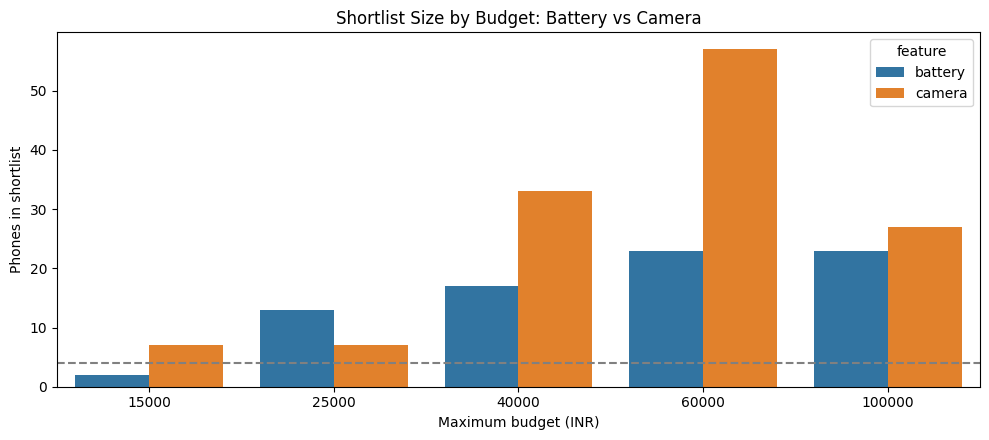

In [58]:
plt.figure(figsize=(10, 4.5))

sns.barplot(
    data=shortlist_behaviour[
        shortlist_behaviour["feature"].isin(["battery", "camera"])
    ],
    x="budget",
    y="shortlisted incl. ties",
    hue="feature"
)

plt.axhline(
    MAX_RESULTS,
    linestyle="--",
    color="grey"
)

plt.title("Shortlist Size by Budget: Battery vs Camera")
plt.xlabel("Maximum budget (INR)")
plt.ylabel("Phones in shortlist")
plt.tight_layout()
plt.show()

The dashed line marks the 4-phone limit. Wherever a bar is above it, the value score decides which 4 shortlisted phones are shown. At most budgets, camera shortlists are larger than battery shortlists because the camera rule has only a few distinct levels, so more phones tie.

### 8. Limitations

- **One feature per request.** Requests combining features ("good battery and good camera") are not handled yet.
- **The camera rule measures camera hardware, not image quality.** The number of useful cameras and whether the sensor is documented are proxies; actual photo and video quality is not in the dataset.
- **Sensor information is assumed for Samsung, Apple, and Google.** These phones count as having sensor information even when `camera_sensor_name` is empty, so this assumption directly affects camera rankings.
- **Value score depends on Part 6.** It reflects specifications relative to price, not software support, after-sales service, or brand reputation.
- **Missing values are excluded.** Phones without a recorded value for a ranking column (for example peak brightness) cannot be shortlisted for that feature.
- **Prices are a snapshot** of the values recorded in the dataset.